# Disfluency-insertion analysis

Clean report on the held-out test set:

1. **Dataset stats** — the human reference set (paper's numbers shown for context).
2. **Reference-based metrics** — BLEU + BERTScore
3. **Token-level evaluation** — micro/macro precision-recall-F1 (+ accuracy, Jaccard, AUC)
4. **Type-specific accuracy** — typical (`<sil>`/filled-pause) vs atypical disfluencies.

Every table shows the **6 fine-tuned runs**, three **naive baselines**, and the **paper's
numbers** as a reference row. Set `DECODING` below to switch between greedy and the sampled
temperatures. For the sampled ones each metric is **averaged over the (3) sampled draws**.

In [27]:
# ============================================================================
# Setup: imports, paths, and which decoding to report.
# ============================================================================
import json, glob, difflib
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (precision_recall_fscore_support, accuracy_score,
                             jaccard_score, roc_auc_score)
from utils.swbd_disfluency_loader import Config, is_fragment, detok, _CLITICS, _PUNCT

pd.set_option("display.float_format", lambda v: f"{v:.2f}")

ROOT = Path("outputs/llm_runs_enriched")          # results directory

# Available decodings. "" = greedy (test_predictions.jsonl); the sampled files carry
# k=3 draws per row in the "predictions" column, which we AVERAGE over. Switch DECODING
# and re-run the notebook to report a different one.
DECODINGS = {"greedy": "", "T=0.5": "_sampled_t05", "T=1.0": "_sampled", "T=1.5": "_sampled_t15"}
DECODING  = "greedy"
CI_METHOD = "normal"      # "t" (Student-t) or "normal" (z) - governs every 95% CI below.
SUFFIX    = DECODINGS[DECODING]
print(f"Reporting decoding = {DECODING!r}  (file suffix {SUFFIX!r})")

cfg = Config()
SIL_TOKEN, FILLER_WORDS, INSERTION_WORDS = cfg.sil_token, cfg.filler_words, cfg.insertion_words
TYPICAL_TYPES  = {"silent_pause", "filled_pause"}            # <sil>, uh, um, ...
ATYPICAL_TYPES = {"reparandum", "fragment", "insertion"}     # repeats, cut-offs, well/like/so

Reporting decoding = 'greedy'  (file suffix '')


In [28]:
# ============================================================================
# Tagging helpers, shared by every metric below.
#   tokenize        whitespace tokenizer; keeps "<sil>" atomic, lowercases, strips edge
#                   punctuation. Both sides of every comparison go through it.
#   tag_prediction  difflib(fluent, text) -> per-token 'O'/'D' via the paper's RULE
#                   (a token is disfluent if it differs from / is absent-from the fluent
#                   text). Applied to any string (human reference OR model output).
#   tag_reference   per-token 'O'/'D' from the GOLD disfl_labels (used only for the
#                   type-specific section, where exact typical/atypical types matter).
#   align_tag_seqs  align two tagged token sequences (difflib) -> aligned tag/type pairs.
#   get_draws       the k sampled predictions for a row (or [prediction] for greedy /
#                   baselines); _pred picks draw d -> lets every metric average over draws.
# ============================================================================
def tokenize(text):
    toks = []
    for t in (text or "").strip().split():
        if t == SIL_TOKEN:
            toks.append(t); continue
        c = t.strip('.,!?;:"()').lower()
        if c: toks.append(c)
    return toks

def tag_prediction(fluent_text, text):
    a, b = tokenize(fluent_text), tokenize(text)
    out = []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(a=a, b=b, autojunk=False).get_opcodes():
        if op == "equal":
            out += [(b[k], "O", None) for k in range(j1, j2)]
        else:
            for k in range(j1, j2):
                tok = b[k]
                ttag = ("silent_pause" if tok == SIL_TOKEN else
                        "filled_pause" if tok in FILLER_WORDS else
                        "insertion"    if tok in INSERTION_WORDS else
                        "fragment"     if is_fragment(tok) else "other_disfl")
                out.append((tok, "D", ttag))
    return out

def tag_reference(tokens, labels):
    return [(t.lower(), "O", None) if l is None else (t.lower(), "D", l)
            for t, l in zip(tokens, labels)]

def align_tag_seqs(ref_seq, pred_seq):
    rt, pt = [x[0] for x in ref_seq], [x[0] for x in pred_seq]
    pairs = []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(a=rt, b=pt, autojunk=False).get_opcodes():
        if op == "equal":
            for d in range(i2 - i1):
                r, p = ref_seq[i1+d], pred_seq[j1+d]; pairs.append((r[1], p[1], r[2], p[2]))
        elif op == "replace":
            n = min(i2 - i1, j2 - j1)
            for d in range(n):
                r, p = ref_seq[i1+d], pred_seq[j1+d]; pairs.append((r[1], p[1], r[2], p[2]))
            for d in range(n, i2-i1): pairs.append((ref_seq[i1+d][1], "O", ref_seq[i1+d][2], None))
            for d in range(n, j2-j1): pairs.append(("O", pred_seq[j1+d][1], None, pred_seq[j1+d][2]))
        elif op == "delete":
            for d in range(i2-i1): pairs.append((ref_seq[i1+d][1], "O", ref_seq[i1+d][2], None))
        elif op == "insert":
            for d in range(j2-j1): pairs.append(("O", pred_seq[j1+d][1], None, pred_seq[j1+d][2]))
    return pairs

def get_draws(row):
    preds = getattr(row, "predictions", None)
    if isinstance(preds, list) and preds:
        return [p or "" for p in preds]
    return [getattr(row, "prediction", "") or ""]

def _pred(row, d):
    dr = get_draws(row)
    return dr[d] if d < len(dr) else dr[-1]


def gold_tags_ws(tokens, labels):
    """Rebuild the GOLD disfluent tokens into the SAME whitespace tokenization used on the
    prediction side (reusing the loader's clitic/punct merge rules), carrying labels: a merged
    token (e.g. "may"+"'ve" -> "may've") is disfluent if ANY of its parts was. Removes the
    PTB-vs-whitespace mismatch so the type-specific alignment is clean, keeping exact gold types."""
    surf, labs = [], []
    for tok, lab in zip(tokens, labels):
        if surf and (tok.lower() in _CLITICS or tok in _PUNCT or tok.startswith("'")):
            surf[-1] = surf[-1] + tok
            if labs[-1] is None:
                labs[-1] = lab                     # disfluency wins on merge
        else:
            surf.append(tok); labs.append(lab)
    out_t, out_l = [], []
    for s, l in zip(surf, labs):
        for t in tokenize(s):                      # strip punct / lowercase / keep <sil>
            out_t.append(t); out_l.append(l)
    return out_t, out_l

def tag_reference_ws(tokens, labels):
    """Like tag_reference, but on the whitespace-consistent gold tokens (see gold_tags_ws)."""
    toks, labs = gold_tags_ws(tokens, labels)
    return [(t, "O", None) if l is None else (t, "D", l) for t, l in zip(toks, labs)]

In [29]:
# ============================================================================
# Naive baselines, added as extra "run"s so every table includes them:
#   baseline_copy            insert nothing (output the fluent sentence)      -> the floor.
#   baseline_random          the human's exact disfluency tokens scattered to RANDOM
#                            positions (token-level). Matches the human count & types but
#                            not placement -> isolates placement skill.
#   baseline_random_typical  same, but only the simple (<sil>/filled-pause) disfluencies
#                            the models actually produce (span-preserving).
# Gold labels are used only to BUILD the baselines; they are scored by the same heuristic
# as the models, so the comparison is fair.
# ============================================================================
def add_baselines(df):
    import random
    rng = random.Random(42)
    df = df[~df["run"].astype(str).str.startswith("baseline_")].copy()
    gold = {}
    with open(ROOT / "splits" / "test.jsonl") as fh:
        for i, line in enumerate(fh):
            r = json.loads(line); gold[(r["conv"], i)] = (r["disfluent_tokens"], r["disfl_labels"])
    TYP = {"silent_pause", "filled_pause"}
    uniq = df.drop_duplicates(subset=["conv", "id"]).copy()
    copy, rand, typ = uniq.copy(), uniq.copy(), uniq.copy()
    for d, name in ((copy, "baseline_copy"), (rand, "baseline_random"), (typ, "baseline_random_typical")):
        d["run"] = name
        for col in ("model_key", "model_id", "context_mode"):
            if col in d.columns: d[col] = name
        if "predictions" in d.columns: d["predictions"] = None   # baselines are a single draw
    copy["prediction"] = copy["fluent"]

    def scatter(conv, id_, fluent, as_spans, only=None):
        g = gold.get((conv, id_))
        if not g: return fluent
        toks, labs = g
        keep = lambda l: (l is not None) and (only is None or l in only)
        if as_spans:                                   # keep contiguous disfluency spans intact
            units, cur = [], []
            for t, l in zip(toks, labs):
                if keep(l): cur.append(t)
                elif cur: units.append(cur); cur = []
            if cur: units.append(cur)
        else:                                          # scatter each disfluency token independently
            units = [[t] for t, l in zip(toks, labs) if keep(l)]
        out = fluent.split()
        for u in units:
            pos = rng.randint(0, len(out)); out[pos:pos] = u    # insert the unit at a random gap
        return " ".join(out)

    rand["prediction"] = [scatter(c, i, f, False)                for c, i, f in zip(rand["conv"], rand["id"], rand["fluent"])]
    typ["prediction"]  = [scatter(c, i, f, True, only=TYP)       for c, i, f in zip(typ["conv"], typ["id"], typ["fluent"])]
    return pd.concat([df, copy, rand, typ], ignore_index=True)

In [30]:
# ============================================================================
# Load the selected decoding's predictions, attach gold token labels, add baselines.
# ============================================================================
def load_predictions(suffix):
    rows = []
    for f in sorted(glob.glob(str(ROOT / f"*/*/test_predictions{suffix}.jsonl"))):
        rows += [json.loads(l) for l in open(f) if l.strip()]
    d = pd.DataFrame(rows)
    d["run"] = d["model_key"] + " / " + d["context_mode"]
    return d

gold_df = (pd.DataFrame([json.loads(l) for l in open(ROOT / "splits" / "test.jsonl")])
           .reset_index().rename(columns={"index": "id"}))

df = load_predictions(SUFFIX)
df = df.merge(gold_df[["conv", "id", "disfluent_tokens", "disfl_labels"]], on=["conv", "id"], how="left")
df = add_baselines(df)

MODEL_RUNS    = sorted(r for r in df["run"].unique() if not r.startswith("baseline_"))
BASELINE_RUNS = ["baseline_copy", "baseline_random", "baseline_random_typical"]
RUN_ORDER     = MODEL_RUNS + BASELINE_RUNS
print(f"{len(df):,} rows | decoding={DECODING} | runs:")
for r in RUN_ORDER: print("  ", r)

16,038 rows | decoding=greedy | runs:
   G4-4EB-it / no_context
   G4-4EB-it / with_context
   L2-7B-Chat / no_context
   L2-7B-Chat / with_context
   L3.1-8B-Instruct / no_context
   L3.1-8B-Instruct / with_context
   baseline_copy
   baseline_random
   baseline_random_typical


In [31]:
# Row counts per model_key x context_mode combo — make sure nothing is missing/duplicated
display(df.groupby(["model_key", "context_mode"]).size().rename("n_rows"))

# Check for nulls in the columns we actually need
display(df[["fluent", "reference", "prediction"]].isna().sum())

model_key                context_mode           
G4-4EB-it                no_context                 1782
                         with_context               1782
L2-7B-Chat               no_context                 1782
                         with_context               1782
L3.1-8B-Instruct         no_context                 1782
                         with_context               1782
baseline_copy            baseline_copy              1782
baseline_random          baseline_random            1782
baseline_random_typical  baseline_random_typical    1782
Name: n_rows, dtype: int64

fluent        0
reference     0
prediction    0
dtype: int64

## 1. Dataset stats
The human (reference) test set. 
Paper's full-set stats: train/test = 32,490 / 3,610 sentences, ~24% fluent / ~33% disfluent tokens, disfluency rate ~24%.

In [32]:
# Stats computed from the gold labels of the unique test sentences.
uniq = df.drop_duplicates(subset=["conv", "id"])
n_dis = n_tok_dis = n_tok_flu = n_typ = n_aty = 0
per_sent = []
for r in uniq.itertuples():
    labs = r.disfl_labels
    d = sum(1 for l in labs if l is not None); per_sent.append(d)
    n_dis += d; n_tok_dis += len(labs); n_tok_flu += sum(1 for l in labs if l is None)
    n_typ += sum(1 for l in labs if l in TYPICAL_TYPES)
    n_aty += sum(1 for l in labs if l in ATYPICAL_TYPES)

pd.Series({
    "n_sentences":               len(uniq),
    "avg_tokens_fluent":         n_tok_flu / len(uniq),
    "avg_tokens_disfluent":      n_tok_dis / len(uniq),
    "disfluency_rate_%":         100 * n_dis / n_tok_dis,
    "disfluencies_per_sentence": np.mean(per_sent),
    "%_typical":                 100 * n_typ / max(n_typ + n_aty, 1),
    "%_atypical":                100 * n_aty / max(n_typ + n_aty, 1),
}, name="our_test_set").to_frame().round(2)

,our_test_set
n_sentences,1782.00
avg_tokens_fluent,16.27
avg_tokens_disfluent,20.87
disfluency_rate_%,22.07
disfluencies_per_sentence,4.61
%_typical,69.84
%_atypical,30.16


## 2. Reference-based metrics (BLEU / BERTScore)
Both are averaged over the sampled draws; BERTScore is raw (`rescale_with_baseline=False`), shown as a percentage. *(This cell loads RoBERTa and can take a few minutes.)*

In [33]:
import sacrebleu
from bert_score import BERTScorer

_scorer = None  # lazy-loaded only if needed

def bleu_bert(g, compute_bert=True):
    rows_ = list(g.itertuples()); k = len(get_draws(rows_[0]))
    refs = [r.reference for r in rows_]

    bl = []
    bp, br, bf = [], [], []

    global _scorer
    if compute_bert and _scorer is None:
        _scorer = BERTScorer(lang="en", rescale_with_baseline=False)

    for d in range(k):
        preds = [_pred(r, d) for r in rows_]
        bl.append(sacrebleu.corpus_bleu(preds, [refs]).score)
        if compute_bert:
            P, R, F = _scorer.score(preds, refs, batch_size=256)
            bp.append(100 * P.mean().item())
            br.append(100 * R.mean().item())
            bf.append(100 * F.mean().item())

    result = dict(BLEU=np.mean(bl))
    if compute_bert:
        result.update(
            BERT_P=np.mean(bp), BERT_R=np.mean(br), BERT_F1=np.mean(bf),
        )
    return result

COMPUTE_BERT = False

ref_tab = pd.DataFrame({
    run: bleu_bert(df[df.run == run], compute_bert=COMPUTE_BERT)
    for run in tqdm(RUN_ORDER, desc="runs")
}).T
ref_tab.loc["— paper: llama-2-7b"]    = {"BLEU": 55.24, "BERT_P": 92.87, "BERT_R": 93.70, "BERT_F1": 93.27}
ref_tab.loc["— paper: flan-t5-large"] = {"BLEU": 44.40, "BERT_P": 96.24, "BERT_R": 91.68, "BERT_F1": 93.86}
ref_tab.round(2)

runs: 100%|██████████| 9/9 [00:01<00:00,  5.17it/s]


,BLEU
G4-4EB-it / no_context,67.11
G4-4EB-it / with_context,67.56
L2-7B-Chat / no_context,67.61
L2-7B-Chat / with_context,67.52
L3.1-8B-Instruct / no_context,68.00
L3.1-8B-Instruct / with_context,68.32
baseline_copy,44.15
baseline_random,55.61
baseline_random_typical,63.82
— paper: llama-2-7b,55.24


## 3. Token-level evaluation
The paper's rule-based tagger is applied to **both** the human reference and model output (`tag_prediction`), then aligned. **Micro** metrics pool all tokens. **Macro** precision, recall, and F1 average sentence-level scores; sampled draws are averaged within each sentence first. The plots report Student-t 95% confidence intervals across those sentence scores.

In [34]:
from scipy.stats import t as student_t, norm

def mean_ci(values, confidence=0.95, method=None):
    """Mean and two-sided 95% CI across the given values, ignoring NaNs.

    method="t"      -> Student-t critical value (default; exact for small n).
    method="normal" -> normal/z critical value (large-n approximation; ~identical
                       to t here). Falls back to the global CI_METHOD when None.
    Each value is one sentence (its sampled draws already averaged), so the
    interval reflects between-sentence variability of the macro mean.
    """
    method = (method or globals().get("CI_METHOD", "t")).lower()
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if not len(x): return np.nan, np.nan, np.nan
    mean = x.mean()
    if len(x) == 1: return mean, mean, mean
    sem = x.std(ddof=1) / np.sqrt(len(x))
    crit = (norm.ppf((1 + confidence) / 2) if method == "normal"
            else student_t.ppf((1 + confidence) / 2, len(x) - 1))
    margin = crit * sem
    return mean, mean - margin, mean + margin

def token_scores(g):
    """Metrics plus 95% CIs across sentence scores (draws averaged per sentence)."""
    rows_ = list(g.itertuples()); k = len(get_draws(rows_[0]))
    pooled_ref, pooled_pred = [[] for _ in range(k)], [[] for _ in range(k)]
    sentence = {m: [] for m in ("P_macro", "R_macro", "F1_macro")}

    for r in rows_:
        per_draw = {m: [] for m in sentence}
        for d in range(k):
            pairs = align_tag_seqs(tag_prediction(r.fluent, r.reference),
                                   tag_prediction(r.fluent, _pred(r, d)))
            ref = [int(x[0] == "D") for x in pairs]
            pred = [int(x[1] == "D") for x in pairs]
            pooled_ref[d].extend(ref); pooled_pred[d].extend(pred)
            if sum(ref) or sum(pred):
                p, rec, f1, _ = precision_recall_fscore_support(
                    ref, pred, average="binary", zero_division=0)
                for m, v in zip(per_draw, (p, rec, f1)):
                    per_draw[m].append(100 * v)
        for m, values in per_draw.items():
            if values: sentence[m].append(np.mean(values))

    draws = defaultdict(list)
    for ref, pred in zip(pooled_ref, pooled_pred):
        p, rec, f1, _ = precision_recall_fscore_support(
            ref, pred, average="binary", zero_division=0)
        draws["P_micro"].append(100 * p); draws["R_micro"].append(100 * rec)
        draws["F1_micro"].append(100 * f1)
        draws["accuracy"].append(100 * accuracy_score(ref, pred))
        draws["jaccard"].append(100 * jaccard_score(ref, pred, zero_division=0))
        draws["auc"].append(roc_auc_score(ref, pred) if len(set(ref)) > 1 else np.nan)

    out = {m: np.nanmean(v) for m, v in draws.items()}
    for m, values in sentence.items():
        out[m], out[f"{m}_ci_low"], out[f"{m}_ci_high"] = mean_ci(values)
    return out

COLS = ["P_micro", "R_micro", "F1_micro", "accuracy", "jaccard", "auc",
        "P_macro", "R_macro", "F1_macro"]
tok_results = pd.DataFrame({
    run: token_scores(df[df.run == run])
    for run in tqdm(RUN_ORDER, desc="token metrics")
}).T
tok_tab = tok_results[COLS].copy()
tok_tab.loc["— paper"] = {"P_micro": 52.2, "R_micro": 85.8, "F1_micro": 61.2,
    "accuracy": 81.6, "jaccard": 30.4, "auc": 0.603,
    "P_macro": 52.2, "R_macro": 85.8, "F1_macro": 61.2}
tok_tab.round(2)

token metrics: 100%|██████████| 9/9 [00:12<00:00,  1.35s/it]


,P_micro,R_micro,F1_micro,accuracy,jaccard,auc,P_macro,R_macro,F1_macro
G4-4EB-it / no_context,67.05,25.20,36.63,80.97,22.42,0.61,62.26,35.23,40.40
G4-4EB-it / with_context,65.77,25.98,37.24,80.93,22.88,0.61,62.36,35.94,40.87
L2-7B-Chat / no_context,64.90,26.02,37.14,80.84,22.81,0.61,62.48,35.84,40.87
L2-7B-Chat / with_context,61.13,26.16,36.64,80.41,22.43,0.61,61.99,35.79,40.68
L3.1-8B-Instruct / no_context,62.88,26.46,37.25,80.67,22.89,0.61,62.04,36.29,41.03
L3.1-8B-Instruct / with_context,65.62,27.39,38.65,81.10,23.95,0.62,62.60,37.44,41.95
baseline_copy,0.00,0.00,0.00,77.55,0.00,0.50,0.00,0.00,0.00
baseline_random,26.70,27.22,26.96,72.16,15.58,0.55,23.07,23.37,23.21
baseline_random_typical,35.37,25.18,29.42,75.89,17.25,0.57,28.66,21.72,24.13
— paper,52.20,85.80,61.20,81.60,30.40,0.60,52.20,85.80,61.20


## 4. Type-specific accuracy (typical vs atypical)
As in the paper (Table 5), the **reference** uses GOLD `disfl_labels` with the same whitespace tokenization as the prediction (`gold_tags_ws`). **Micro** metrics are token-pooled. **Macro** precision, recall, and F1 average sentence-level scores, skipping sentences where the metric is undefined for that type; sampled draws are averaged within each sentence first. The plots show Student-t 95% confidence intervals across sentences.

In [35]:
def bucket(t):
    if t in TYPICAL_TYPES: return "typical"
    if t in ATYPICAL_TYPES or t == "other_disfl": return "atypical"
    return None

def _harmonic(p, rec):
    if not np.isfinite(p) or not np.isfinite(rec): return np.nan
    return 2 * p * rec / (p + rec) if p + rec else 0.0

def type_scores(g):
    """Type metrics plus 95% CIs across sentence scores (draws averaged per sentence)."""
    rows_ = list(g.itertuples()); k = len(get_draws(rows_[0]))
    out = {}
    for group in ("typical", "atypical"):
        totals = [dict(rh=0, rt=0, ph=0, pt=0) for _ in range(k)]
        sentence = {m: [] for m in ("precision", "recall", "f1")}
        for r in rows_:
            per_draw = {m: [] for m in sentence}
            for d in range(k):
                pairs = align_tag_seqs(tag_reference_ws(r.disfluent_tokens, r.disfl_labels),
                                       tag_prediction(r.fluent, _pred(r, d)))
                rh = rt = ph = pt = 0
                for rtag, ptag, rtype, ptype in pairs:
                    if rtag == "D" and bucket(rtype) == group:
                        rt += 1; rh += ptag == "D"
                    if ptag == "D" and bucket(ptype) == group:
                        pt += 1; ph += rtag == "D"
                for key, value in zip(("rh", "rt", "ph", "pt"), (rh, rt, ph, pt)):
                    totals[d][key] += value

                p = 100 * ph / pt if pt else np.nan
                rec = 100 * rh / rt if rt else np.nan
                f1 = _harmonic(p if pt else 0.0, rec if rt else 0.0) if rt or pt else np.nan
                for m, value in zip(per_draw, (p, rec, f1)):
                    if np.isfinite(value): per_draw[m].append(value)
            for m, values in per_draw.items():
                if values: sentence[m].append(np.mean(values))

        micro = {m: [] for m in ("precision", "recall", "f1")}
        for t in totals:
            p = 100 * t["ph"] / t["pt"] if t["pt"] else np.nan
            rec = 100 * t["rh"] / t["rt"] if t["rt"] else np.nan
            for m, value in zip(micro, (p, rec, _harmonic(p, rec))):
                micro[m].append(value)
        for m, values in micro.items():
            out[f"{group}_{m}_micro"] = np.nanmean(values)
        for m, values in sentence.items():
            mean, low, high = mean_ci(values)
            out[f"{group}_{m}_macro"] = mean
            out[f"{group}_{m}_macro_ci_low"] = low
            out[f"{group}_{m}_macro_ci_high"] = high
    return out

_ts = pd.DataFrame({
    run: type_scores(df[df.run == run])
    for run in tqdm(RUN_ORDER, desc="type metrics")
}).T

def type_view(kind):
    metrics = [f"{group}_{metric}" for group in ("typical", "atypical")
               for metric in ("precision", "recall", "f1")]
    v = _ts[[f"{m}_{kind}" for m in metrics]].copy()
    v.columns = metrics
    if kind == "macro":
        for m in metrics:
            v[f"{m}_ci_low"] = _ts[f"{m}_macro_ci_low"]
            v[f"{m}_ci_high"] = _ts[f"{m}_macro_ci_high"]
    v.loc["— paper: SIL (typical)"] = {"typical_precision": 49.5, "typical_recall": 93.4}
    v.loc["— paper: DISFL (atypical)"] = {"atypical_precision": 53.4, "atypical_recall": 82.5}
    return v.round(2)

print("Type-specific — MICRO (token-pooled):")
display(type_view("micro"))
print("\nType-specific — MACRO (sentence means with 95% CIs):")
display(type_view("macro"))

type metrics:  67%|██████▋   | 6/9 [00:01<00:00,  4.59it/s]C:\Users\saba\AppData\Local\Temp\ipykernel_81692\2258816695.py:46: RuntimeWarning: Mean of empty slice
  out[f"{group}_{m}_micro"] = np.nanmean(values)
type metrics: 100%|██████████| 9/9 [00:02<00:00,  4.47it/s]

Type-specific — MICRO (token-pooled):


,typical_precision,typical_recall,typical_f1,atypical_precision,atypical_recall,atypical_f1
G4-4EB-it / no_context,67.75,34.53,45.75,29.03,1.99,3.72
G4-4EB-it / with_context,67.11,35.21,46.19,30.17,3.15,5.71
L2-7B-Chat / no_context,66.00,35.39,46.07,24.73,2.72,4.91
L2-7B-Chat / with_context,63.57,35.46,45.52,17.00,2.81,4.82
L3.1-8B-Instruct / no_context,65.41,36.01,46.45,12.50,2.72,4.47
L3.1-8B-Instruct / with_context,66.89,36.97,47.62,31.54,3.59,6.44
baseline_copy,NaN,0.00,NaN,NaN,0.00,NaN
baseline_random,30.28,31.22,30.74,17.44,16.51,16.96
baseline_random_typical,35.44,34.16,34.79,NaN,3.15,NaN
— paper: SIL (typical),49.50,93.40,NaN,NaN,NaN,NaN



Type-specific — MACRO (sentence means with 95% CIs):


,typical_precision,typical_recall,typical_f1,atypical_precision,atypical_recall,atypical_f1,typical_precision_ci_low,typical_precision_ci_high,typical_recall_ci_low,typical_recall_ci_high,typical_f1_ci_low,typical_f1_ci_high,atypical_precision_ci_low,atypical_precision_ci_high,atypical_recall_ci_low,atypical_recall_ci_high,atypical_f1_ci_low,atypical_f1_ci_high
G4-4EB-it / no_context,62.58,41.81,45.24,31.13,2.39,0.86,60.49,64.68,40.02,43.59,43.51,46.97,18.69,43.58,1.58,3.21,0.40,1.33
G4-4EB-it / with_context,62.86,42.19,45.48,42.56,4.42,1.80,60.78,64.94,40.40,43.97,43.75,47.22,30.73,54.40,3.26,5.58,1.06,2.55
L2-7B-Chat / no_context,62.78,42.48,45.58,35.31,3.46,1.12,60.69,64.87,40.70,44.27,43.85,47.31,23.46,47.16,2.46,4.45,0.56,1.68
L2-7B-Chat / with_context,62.47,42.24,45.32,33.86,3.53,1.55,60.38,64.56,40.46,44.02,43.60,47.04,23.98,43.74,2.53,4.53,0.90,2.20
L3.1-8B-Instruct / no_context,62.58,42.95,45.88,22.33,3.50,1.11,60.50,64.65,41.16,44.75,44.14,47.61,13.00,31.67,2.49,4.51,0.55,1.67
L3.1-8B-Instruct / with_context,62.94,44.09,46.67,41.09,4.64,2.24,60.89,64.99,42.29,45.88,44.95,48.40,31.20,50.97,3.46,5.81,1.45,3.02
baseline_copy,NaN,0.00,0.00,NaN,0.00,0.00,NaN,NaN,0.00,0.00,0.00,0.00,NaN,NaN,0.00,0.00,0.00,0.00
baseline_random,24.87,25.64,24.62,16.92,16.08,13.47,23.55,26.19,24.30,26.99,23.31,25.93,15.07,18.77,14.23,17.93,11.77,15.17
baseline_random_typical,29.45,28.36,28.64,NaN,2.78,0.00,27.87,31.03,26.82,29.90,27.09,30.19,NaN,NaN,1.94,3.62,0.00,0.00
— paper: SIL (typical),49.50,93.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Visual comparison

The plots below reuse the tables computed above. Runs from the same base model share a hue; **with-context** runs use the darker shade and **no-context** runs use the lighter shade. Naive baselines are gray. Paper results and the held-out human test set are shown as dashed reference lines/bands.


,disfluency_rate_mean,disfluency_rate_ci_low,disfluency_rate_ci_high,disfluencies_per_sentence_mean,disfluencies_per_sentence_ci_low,disfluencies_per_sentence_ci_high
G4-4EB-it / no_context,10.02,9.78,10.26,1.70,1.64,1.75
G4-4EB-it / with_context,10.33,10.07,10.59,1.79,1.70,1.87
L2-7B-Chat / no_context,10.39,10.11,10.66,1.81,1.71,1.91
L2-7B-Chat / with_context,10.60,10.27,10.92,1.93,1.78,2.09
L3.1-8B-Instruct / no_context,10.60,10.31,10.90,1.90,1.78,2.02
L3.1-8B-Instruct / with_context,10.75,10.48,11.02,1.89,1.80,1.98
baseline_copy,0.00,0.00,0.00,0.00,0.00,0.00
baseline_random,21.44,20.89,21.99,4.61,4.43,4.79
baseline_random_typical,16.36,15.92,16.80,3.22,3.10,3.34
human test set,20.75,20.21,21.29,4.61,4.43,4.79


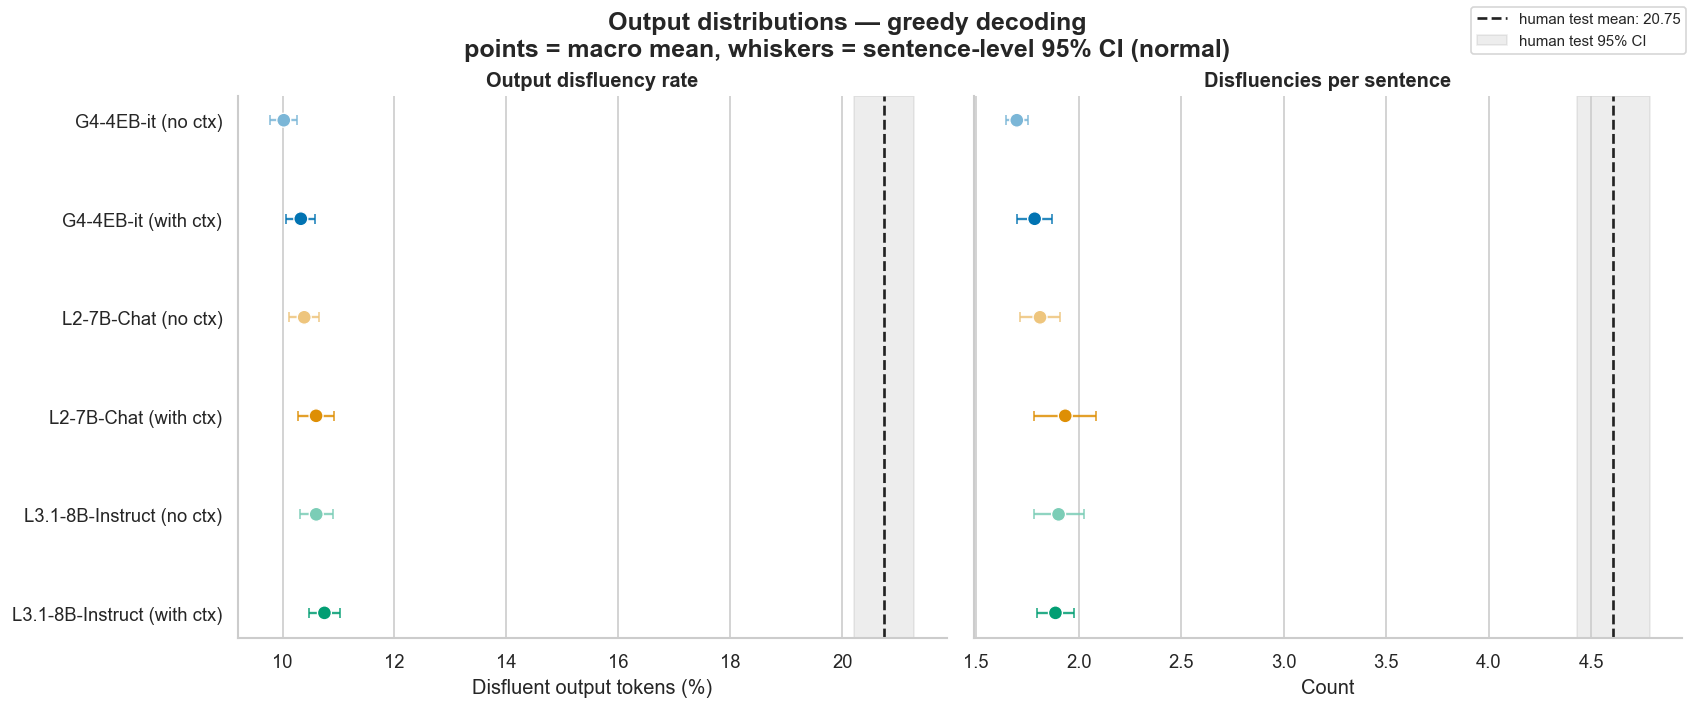

In [36]:
# Shared plotting style and mean output-disfluency summaries.
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgb

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})

# --- Section-5 display knobs -------------------------------------------------
SHOW_CI  = True        # draw 95% CI whiskers on the macro P/R/F1 + type panels
CI_CLAMP = (0, 100)    # metrics are bounded -> clip drawn CI whiskers to this range
# (Student-t vs normal is chosen by CI_METHOD in the setup cell and baked into the
#  tables upstream; re-run the metric cells after changing it.)

def _blend(color, toward="white", amount=0.35):
    a, b = np.array(to_rgb(color)), np.array(to_rgb(toward))
    return tuple((1 - amount) * a + amount * b)

def _run_parts(run):
    return (run, "baseline") if run.startswith("baseline_") else run.split(" / ", 1)

MODELS = list(dict.fromkeys(_run_parts(r)[0] for r in MODEL_RUNS))
_base_colors = dict(zip(MODELS, sns.color_palette("colorblind", len(MODELS))))
PLOT_RUNS = MODEL_RUNS

def run_color(run):
    model, context = _run_parts(run)
    if context == "baseline": return "#9a9a9a"
    return _base_colors[model] if context == "with_context" else _blend(_base_colors[model], amount=0.48)

def run_label(run):
    if run.startswith("baseline_"):
        return run.replace("baseline_", "baseline: ").replace("_", " ")
    model, context = _run_parts(run)
    return f"{model} ({'with ctx' if context == 'with_context' else 'no ctx'})"

def output_means(g):
    """Per-sentence disfluency rate/count (draws averaged within sentence), then the
    macro mean and 95% CI across sentences — same sentence-level scheme as the metric
    panels, so these point summaries carry matching uncertainty."""
    rate_sent, count_sent = [], []
    for r in g.itertuples():
        r_draws, c_draws = [], []
        for pred in get_draws(r):
            seq = tag_prediction(r.fluent, pred)
            count = sum(tag == "D" for _, tag, _ in seq)
            r_draws.append(100 * count / max(len(seq), 1)); c_draws.append(count)
        rate_sent.append(np.mean(r_draws)); count_sent.append(np.mean(c_draws))
    out = {}
    for base, vals in (("disfluency_rate", rate_sent),
                       ("disfluencies_per_sentence", count_sent)):
        m, lo, hi = mean_ci(vals)
        out[f"{base}_mean"], out[f"{base}_ci_low"], out[f"{base}_ci_high"] = m, lo, hi
    return out

rate_tab = pd.DataFrame({run: output_means(df[df.run == run]) for run in RUN_ORDER}).T
gold_counts = [sum(label is not None for label in r.disfl_labels) for r in uniq.itertuples()]
gold_rates = [100 * count / max(len(r.disfl_labels), 1)
              for count, r in zip(gold_counts, uniq.itertuples())]
grate_m, grate_lo, grate_hi = mean_ci(gold_rates)
gcount_m, gcount_lo, gcount_hi = mean_ci(gold_counts)
rate_tab.loc["human test set"] = {
    "disfluency_rate_mean": grate_m,
    "disfluency_rate_ci_low": grate_lo, "disfluency_rate_ci_high": grate_hi,
    "disfluencies_per_sentence_mean": gcount_m,
    "disfluencies_per_sentence_ci_low": gcount_lo,
    "disfluencies_per_sentence_ci_high": gcount_hi,
}
display(rate_tab.round(2))

def plot_output_means(ax, column, title, xlabel):
    y = np.arange(len(PLOT_RUNS))
    means = rate_tab.loc[PLOT_RUNS, column].astype(float)
    base = column[:-len("_mean")]                       # -> "..._ci_low/_ci_high"
    is_rate = column == "disfluency_rate_mean"          # a % (bounded); counts are not
    if SHOW_CI:
        lo = rate_tab.loc[PLOT_RUNS, f"{base}_ci_low"].astype(float)
        hi = rate_tab.loc[PLOT_RUNS, f"{base}_ci_high"].astype(float)
        if is_rate: lo, hi = lo.clip(*CI_CLAMP), hi.clip(*CI_CLAMP)
        lower = np.nan_to_num(np.maximum(0, means - lo))
        upper = np.nan_to_num(np.maximum(0, hi - means))
        for yi, m, le, ue, run in zip(y, means, lower, upper, PLOT_RUNS):
            ax.errorbar(m, yi, xerr=[[le], [ue]], fmt="none",
                        ecolor=run_color(run), elinewidth=1.4, capsize=3,
                        alpha=0.85, zorder=2)
    ax.scatter(means, y, c=[run_color(r) for r in PLOT_RUNS], s=70,
               zorder=3, edgecolor="white", linewidth=0.8)
    test_mean = rate_tab.loc["human test set", column]
    ax.axvline(test_mean, color="#222222", linestyle="--", linewidth=1.6,
               label=f"human test mean: {test_mean:.2f}")
    if SHOW_CI:
        tlo = rate_tab.loc["human test set", f"{base}_ci_low"]
        thi = rate_tab.loc["human test set", f"{base}_ci_high"]
        if np.isfinite(tlo) and np.isfinite(thi):
            tlo = max(0, tlo)
            if is_rate: thi = min(CI_CLAMP[1], thi)
            ax.axvspan(tlo, thi, color="#222222", alpha=0.08, zorder=0,
                       label="human test 95% CI")
    ax.set_yticks(y, [run_label(r) for r in PLOT_RUNS]); ax.invert_yaxis()
    ax.set_title(title, weight="bold"); ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False);

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), constrained_layout=True)
plot_output_means(axes[0], "disfluency_rate_mean",
                  "Output disfluency rate", "Disfluent output tokens (%)")
plot_output_means(axes[1], "disfluencies_per_sentence_mean",
                  "Disfluencies per sentence", "Count")
axes[1].tick_params(labelleft=False)
ci_note = (f"points = macro mean, whiskers = sentence-level 95% CI ({CI_METHOD})"
           if SHOW_CI else "points = macro mean (SHOW_CI = False)")
fig.suptitle(f"Output distributions — {DECODING} decoding\n{ci_note}",
             fontsize=15, weight="bold")
handles, labels = axes[0].get_legend_handles_labels()
seen = dict(zip(labels, handles))
fig.legend(seen.values(), seen.keys(), loc="upper right", frameon=True, fontsize=9)

plt.show()

### Reference-based and token-level metrics

BLEU and BERTScore F1 show **means only**. Macro precision, recall, and F1 show 95% confidence intervals across sentence-level scores (toggle with `SHOW_CI`; Student-t or normal via `CI_METHOD`). For sampled decoding the three draws are averaged within each sentence before the interval is computed. Dashed lines reproduce the paper values entered above.

The BERTScore panel appears only when `COMPUTE_BERT = True` was set upstream; otherwise just BLEU is shown.


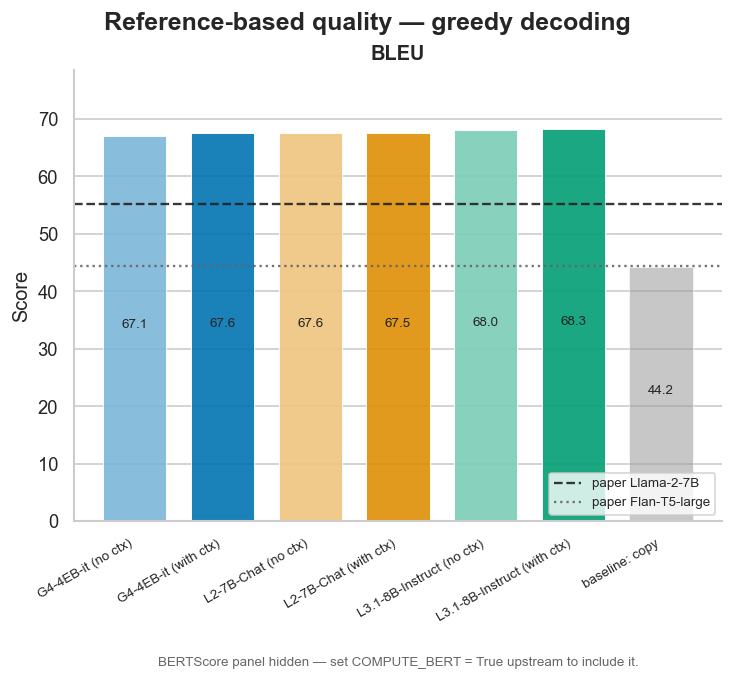

In [37]:
# Shared bar-plot helper + reference-based figure (means only).
# Baselines: keep only the ones informative for each comparison.
REF_RUNS = MODEL_RUNS + ["baseline_copy"]
TOK_RUNS = MODEL_RUNS + ["baseline_random", "baseline_random_typical"]

def metric_bars(ax, values, title, ylabel, runs, paper_lines=(),
                show_legend=False, ci=None):
    """Bar chart of `values` over `runs`. If `ci=(low, high)` Series are supplied and
    SHOW_CI is on, draw 95% CI whiskers (clipped to CI_CLAMP; NaNs -> no whisker)."""
    means = values.loc[runs].astype(float)
    x = np.arange(len(runs))
    yerr, upper = None, means.copy()
    if ci is not None and SHOW_CI:
        low  = ci[0].loc[runs].astype(float).clip(*CI_CLAMP)
        high = ci[1].loc[runs].astype(float).clip(*CI_CLAMP)
        lower_err = np.nan_to_num(np.maximum(0, means - low))
        upper_err = np.nan_to_num(np.maximum(0, high - means))
        yerr = np.vstack([lower_err, upper_err])
        upper = high

    bars = ax.bar(x, means, yerr=yerr, color=[run_color(r) for r in runs],
                  width=0.72, capsize=3, edgecolor="white", linewidth=0.6,
                  error_kw={"elinewidth": 1.4, "ecolor": "#333333", "alpha": 0.85})
    for bar, run in zip(bars, runs):
        bar.set_alpha(0.55 if run.startswith("baseline_") else 0.9)
    for label, value, color, style in paper_lines:
        ax.axhline(value, color=color, linestyle=style, linewidth=1.4,
                   alpha=0.9, label=label)

    ax.set_title(title, weight="bold", fontsize=12); ax.set_ylabel(ylabel)
    ax.set_xticks(x, [run_label(r) for r in runs], rotation=30, ha="right", fontsize=8)
    ax.grid(axis="x", visible=False)
    candidates = upper[np.isfinite(upper)].tolist() + [v for _, v, _, _ in paper_lines]
    ax.set_ylim(0, min(100, max(candidates, default=100) * 1.15))
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8, label_type="center")
    if show_legend and paper_lines:
        ax.legend(fontsize=8, loc="lower right", frameon=True)

paper_bleu = [("paper Llama-2-7B", 55.24, "#222222", "--"),
              ("paper Flan-T5-large", 44.40, "#666666", ":")]
paper_bert_f1 = [("paper Llama-2-7B", 93.27, "#222222", "--"),
                 ("paper Flan-T5-large", 93.86, "#666666", ":")]
paper_macro = {
    "P_macro":  [("paper", 52.2, "#222222", "--")],
    "R_macro":  [("paper", 85.8, "#222222", "--")],
    "F1_macro": [("paper", 61.2, "#222222", "--")],
}

# BLEU is always present; BERTScore only when COMPUTE_BERT was on upstream.
ref_panels = [("BLEU", "BLEU", "Score", paper_bleu)]
if "BERT_F1" in ref_tab.columns:
    ref_panels.append(("BERT_F1", "BERTScore F1", "Score (%)", paper_bert_f1))

fig1, axes1 = plt.subplots(1, len(ref_panels), figsize=(6 * len(ref_panels), 5.5),
                           constrained_layout=True, squeeze=False)
for ax, (col, title, ylab, plines) in zip(axes1[0], ref_panels):
    metric_bars(ax, ref_tab[col], title, ylab, REF_RUNS, plines, show_legend=True)
fig1.suptitle(f"Reference-based quality — {DECODING} decoding",
              fontsize=15, weight="bold")
if "BERT_F1" not in ref_tab.columns:
    axes1[0][0].text(
        0.5, -0.30,
        "BERTScore panel hidden — set COMPUTE_BERT = True upstream to include it.",
        transform=axes1[0][0].transAxes, ha="center", va="top",
        fontsize=8, color="#666666")
plt.show()


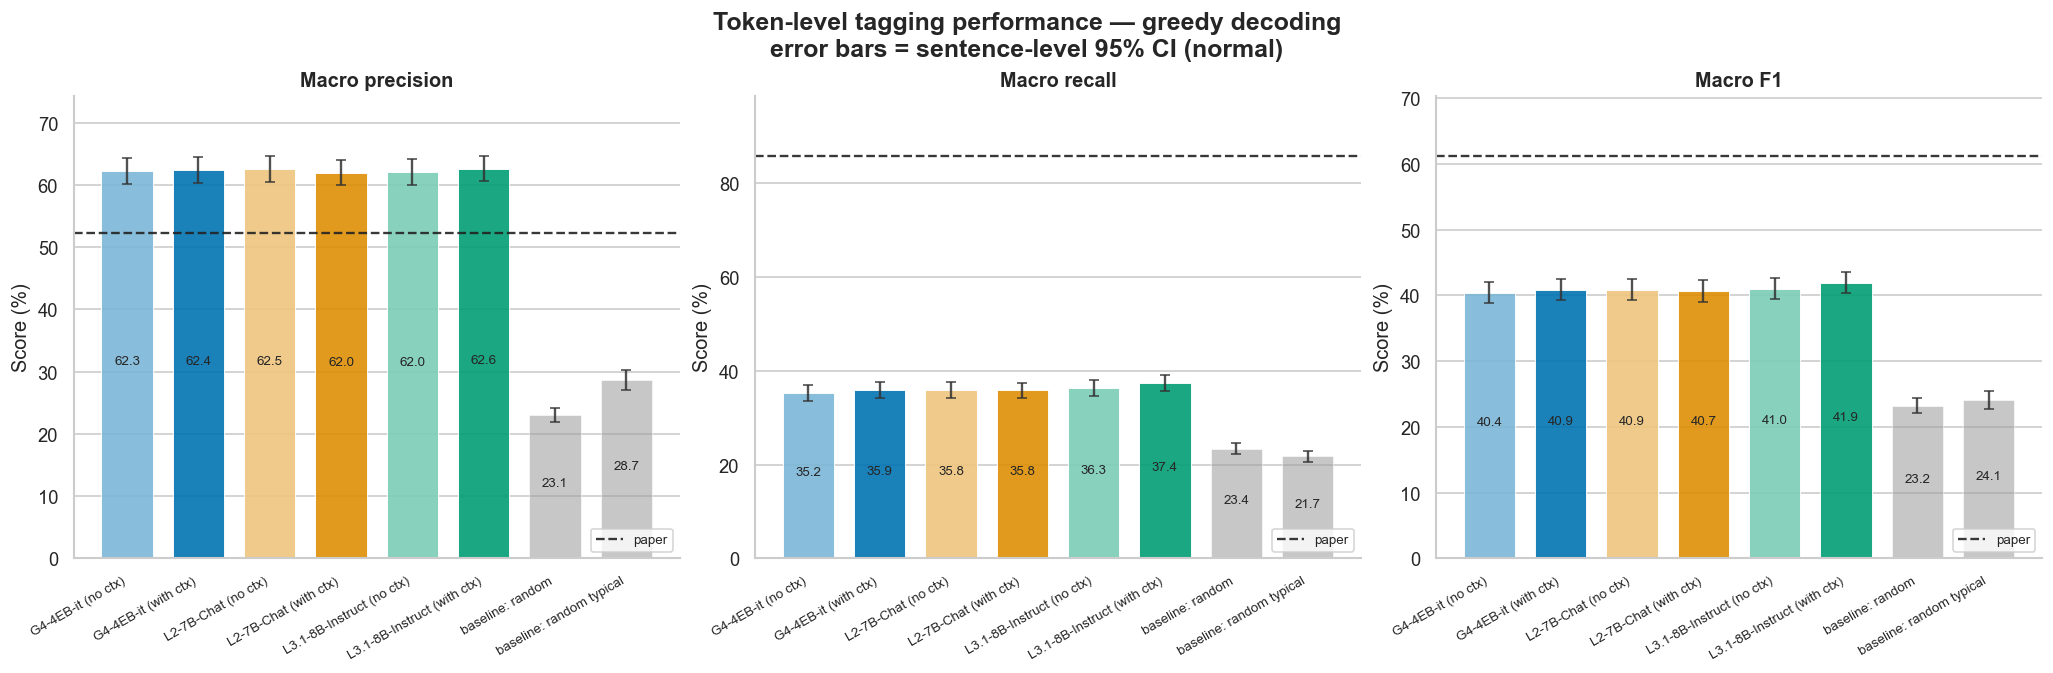

In [38]:
# Token-level macro P/R/F1 — means, with optional sentence-level 95% CIs.
fig2, axes2 = plt.subplots(1, 3, figsize=(17, 5.5), constrained_layout=True)
for ax, metric, title in zip(
    axes2, ("P_macro", "R_macro", "F1_macro"),
    ("Macro precision", "Macro recall", "Macro F1"),
):
    metric_bars(
        ax, tok_tab[metric], title, "Score (%)", TOK_RUNS,
        paper_macro[metric], show_legend=True,
        ci=(tok_results[f"{metric}_ci_low"], tok_results[f"{metric}_ci_high"]),
    )
ci_note = (f"error bars = sentence-level 95% CI ({CI_METHOD})"
           if SHOW_CI else "means only (SHOW_CI = False)")
fig2.suptitle(f"Token-level tagging performance — {DECODING} decoding\n{ci_note}",
              fontsize=15, weight="bold")
plt.show()


### Typical vs atypical disfluencies

These panels show macro precision, recall, and F1 with sentence-level 95% confidence intervals. The paper reports precision and recall for SIL/DISFL, so the F1 panels have no paper reference line.


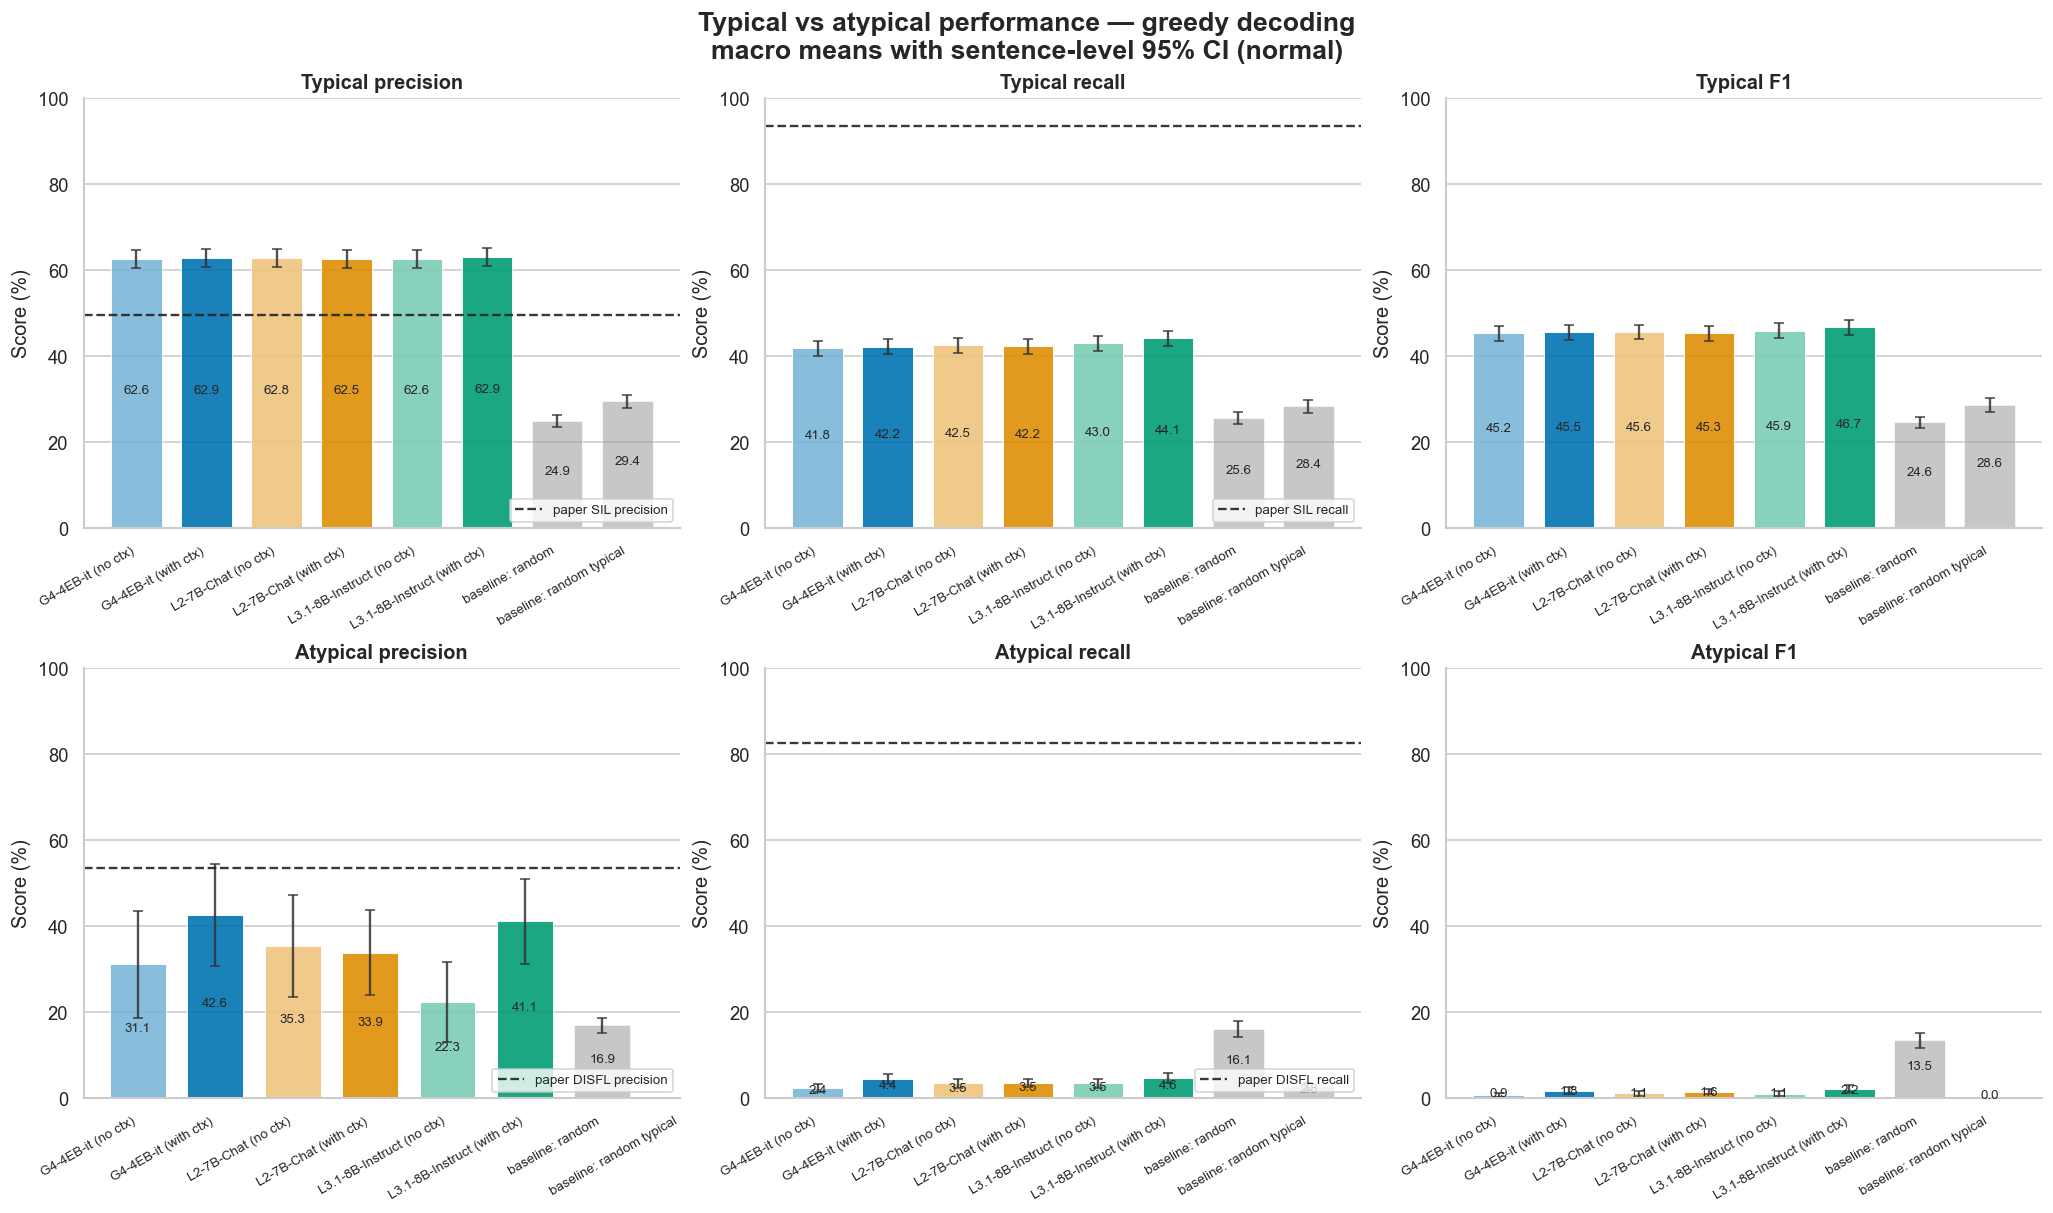

In [39]:
# Typical vs atypical macro P/R/F1 — means, with optional sentence-level 95% CIs.
type_macro = type_view("macro")
type_specs = [
    ("typical_precision",  "Typical precision",  49.5, "paper SIL precision"),
    ("typical_recall",     "Typical recall",     93.4, "paper SIL recall"),
    ("typical_f1",         "Typical F1",         None, None),
    ("atypical_precision", "Atypical precision", 53.4, "paper DISFL precision"),
    ("atypical_recall",    "Atypical recall",    82.5, "paper DISFL recall"),
    ("atypical_f1",        "Atypical F1",        None, None),
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10), constrained_layout=True)
for ax, (metric, title, paper_value, paper_label) in zip(axes.flat, type_specs):
    paper_line = ([(paper_label, paper_value, "#222222", "--")]
                  if paper_value is not None else [])
    metric_bars(
        ax, type_macro[metric], title, "Score (%)", TOK_RUNS,
        paper_line, show_legend=bool(paper_line),
        ci=(type_macro[f"{metric}_ci_low"], type_macro[f"{metric}_ci_high"]),
    )
    ax.set_ylim(0, 100)

ci_note = (f"macro means with sentence-level 95% CI ({CI_METHOD})"
           if SHOW_CI else "macro means only (SHOW_CI = False)")
fig.suptitle(f"Typical vs atypical performance — {DECODING} decoding\n{ci_note}",
             fontsize=16, weight="bold")
plt.show()
